# xView: Raster Data Engineering

> This notebook demonstrates using a distributed raster API to load TIFs into Lakehouse tables + clip objects.

<img src="https://geospatialmedia.s3.amazonaws.com/wp-content/uploads/2018/02/example6.jpg" width="50%"/>
</p>
<img src="https://geospatialmedia.s3.amazonaws.com/wp-content/uploads/2018/02/Screen-Shot-2018-02-23-at-6.22.39-PM.png" width="50%"/>

---
_Last Modified:_ June 19, 2026

![xView — clip aerial rasters to labeled objects](https://raw.githubusercontent.com/databrickslabs/geobrix/main/resources/images/diagrams/xview/xview-clipping.png)


## [1] Setup

> More about the surfaces and levels at [Surfaces and levels](https://databrickslabs.github.io/geobrix/docs/api/execution-tiers)

In [0]:
%pip install --quiet --disable-pip-version-check --force-reinstall --no-deps "geobrix @ file:///Volumes/geospatial_docs/geobrix/sample-data/geobrix-0.6.0+env6-py3-none-any.whl"
%pip install --quiet "geobrix[vizx] @ file:///Volumes/geospatial_docs/geobrix/sample-data/geobrix-0.6.0+env6-py3-none-any.whl"

GeoBrix 0.6.0+env6 installed (build b5dbc078163e, wheel sha256 244b89185146) on Serverless environment 6


In [0]:
dbutils.library.restartPython()

In [0]:
# Force every tableExists() guard below to rebuild (don't skip any logic).
FORCE_REBUILD = False  # rebuild all tables every run; set False to reuse tables that already exist

In [0]:
INTERACTIVE_PLOTS = False

In [0]:
# replace with your catalog and schema
catalog_name = "geospatial_docs"
schema_name = "xview"

sql(f"""USE CATALOG {catalog_name}""")
sql(f"""CREATE DATABASE IF NOT EXISTS {schema_name}""")
sql(f"""USE DATABASE {schema_name}""")

print(f"... catalog: '{catalog_name}' (USE)")
print(f"... schema: '{schema_name}' (CREATE / USE)")

... catalog: 'geospatial_docs' (USE)
... schema: 'xview' (CREATE / USE)


In [0]:
VOL_BASE_DIR = f"/Volumes/{catalog_name}/{schema_name}/data"
VOL_TIFF_DIR = f"{VOL_BASE_DIR}/train_images"
VOL_LABELS_GEOJSON = f"{VOL_BASE_DIR}/train_labels/xView_train.geojson"

In [0]:
from pyspark.sql import functions as F
from pyspark.databricks.sql import functions as DBF

In [0]:
# -- geobrix: the rx.rst_* python functions (just pip install the env wheel)
from databricks.labs.gbx.rasterx import functions as rx

In [0]:
# register the SQL functions and the *_gbx readers and writers
from databricks.labs import gbx
_ = gbx.register(spark)

geobrix 0.6.0: one wheel per runtime (+env5 / +env6); SQL functions register through databricks.labs.gbx.register(spark); the Python API is rasterx / gridx / vectorx. See https://databrickslabs.github.io/geobrix/docs/migration-0-6
geobrix: heavy (Catalyst) unavailable: Spark Connect session (Serverless); using light (48 functions)
geobrix: SQL unavailable: 5 functions (gbx_bng_cellarea, gbx_bng_eastnorthasbng, gbx_quadbin_distance, ...) need a SQL function wrapper, and SQL functions are unavailable here; using light


In [0]:
# -- optional Spark conf tuning, guarded for Serverless (no-ops there) --
def set_conf_safe(key, value):
  try:
    spark.conf.set(key, value)
    return True
  except Exception as e:
    print(f"... skipping spark.conf.set({key}) [Serverless?]: {type(e).__name__}")
    return False

# https://spark.apache.org/docs/latest/configuration.html
# set_conf_safe("spark.sql.adaptive.coalescePartitions.enabled", "false")
# set_conf_safe("spark.sql.shuffle.partitions", 512)

# Raster previews use the tier-agnostic VizX helpers (geobrix[vizx]) instead of
# a hand-rolled rasterio.plot wrapper: they add decimation, a percentile stretch
# for high-bit-depth imagery, and nodata masking, and handle dbfs:-qualified paths.
from databricks.labs.gbx.vizx import plot_raster, plot_file, as_gdf

### Download xView Data

> You have to go to https://challenge.xviewdataset.org/welcome and setup an account, then you can proceed with your session-based links from https://challenge.xviewdataset.org/download-links; we are using the TGZ links.

In [0]:
import os
import shutil
from pathlib import Path

def clean_tmp_dir(folder_name):
    """
    For manual cleanup
    """
    local_scratch = Path(f"/tmp/{folder_name}")
    if local_scratch.exists(): shutil.rmtree(local_scratch)


def clean_local_scratch(final_folder_name):
    clean_tmp_dir(f"extract_{final_folder_name}")

In [0]:
def download_extract(url, target_base_dir, folder_name):
    """
    Extracts to local /tmp via shell and copies to Volume via shell.
    Bypasses dbutils permission restrictions.
    """
    # 1. Setup Paths
    vol_final_dir = Path(f"{target_base_dir}/{folder_name}").absolute()
    local_scratch = Path(f"/tmp/extract_{folder_name}")
    
    # 2. Skip if already exists on Volume
    if vol_final_dir.exists() and any(vol_final_dir.iterdir()):
        print(f"✅ {folder_name} already exists on Volume. Skipping.")
        return

    # 3. Prepare Local SSD
    clean_local_scratch(folder_name)
    local_scratch.mkdir(parents=True, exist_ok=True)
    vol_final_dir.mkdir(parents=True, exist_ok=True)

    print(f"🚀 Streaming from URL to local SSD (/tmp)...")
    
    # We extract into /tmp. We don't use --strip-components here to be safe.
    # We let tar do whatever it wants inside /tmp.
    extract_cmd = (
        f"curl -L '{url}' | "
        f"tar -xz -C '{local_scratch}' "
        f"--exclude='._*' --exclude='__MACOSX' --exclude='.DS_Store'"
    )
    
    if os.system(extract_cmd) != 0:
        print("❌ Extraction failed.")
        return

    # 4. Find the actual data (Solving the Nesting Problem)
    # We look for where the first .tif file is to identify the real data folder
    print("🔍 Locating images and flattening structure...")
    # This shell command finds the directory containing the first .tif file
    find_cmd = f"find {local_scratch} -name '*.tif' -print -quit | xargs dirname"
    actual_data_source = os.popen(find_cmd).read().strip()

    if not actual_data_source:
        print("❌ Could not find any images in the extracted archive.")
        return

    print(f"📂 Found data in: {actual_data_source}")

    # 5. Fast Shell Copy from /tmp to Volume
    # 'cp -rp' copies contents recursively and preserves attributes.
    # We use '/.' at the end of the source to copy contents, NOT the folder itself.
    print(f"📤 Uploading to Volume: {vol_final_dir}...")
    
    # This is the fastest move possible on Databricks because it uses the 
    # OS-level optimized copy buffer.
    copy_cmd = f"cp -rp '{actual_data_source}/.' '{vol_final_dir}/'"
    
    if os.system(copy_cmd) == 0:
        print(f"✨ Successfully moved data to {vol_final_dir}")
    else:
        print("❌ Failed to copy data to Volume. Check Volume space.")

    # 6. Cleanup Local SSD
    print("🧹 Cleaning up local scratch...")
    shutil.rmtree(local_scratch)

In [0]:
labels_url = "<from xView>"
download_extract(labels_url, VOL_BASE_DIR, "train_labels")

✅ train_labels already exists on Volume. Skipping.


In [0]:
train_url = "<from xView>"
download_extract(train_url, VOL_BASE_DIR, "train_images")

✅ train_images already exists on Volume. Skipping.


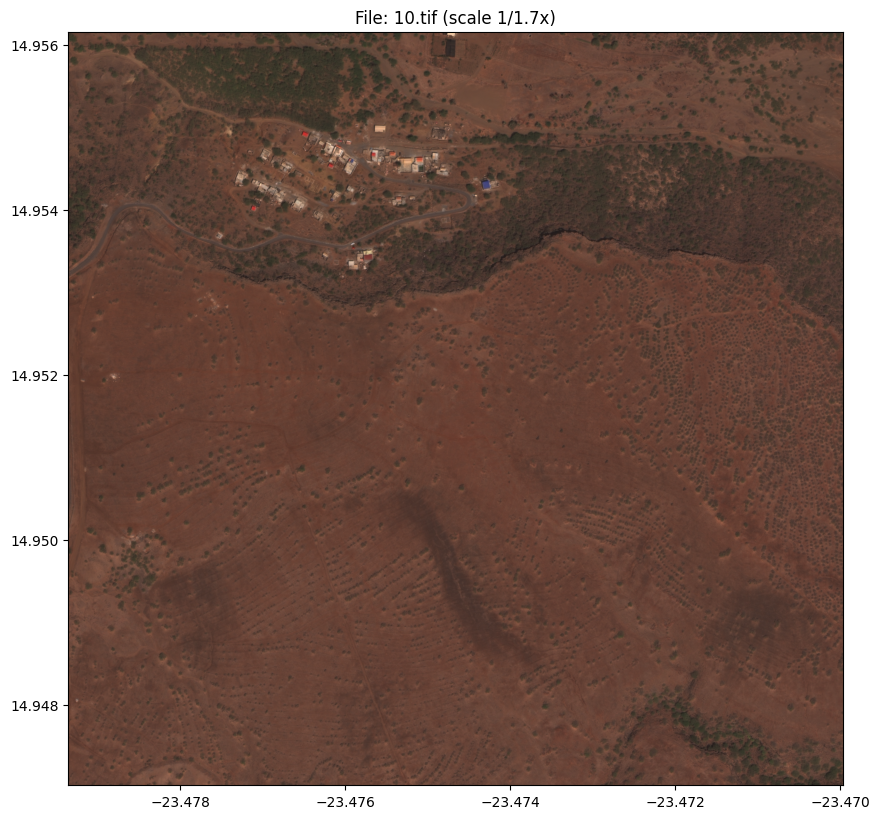

<Axes: title={'center': 'File: 10.tif (scale 1/1.7x)'}>

In [0]:
plot_file(f"{VOL_BASE_DIR}/train_images/10.tif")

## [2] Load Rasters

__Load from Volume.__

> For rendering, see https://docs.databricks.com/aws/en/query/formats/binary

_Uncomment the following within databricks for actual results._ 

In [0]:
displayHTML("""<img src="data:image/jpeg;base64, ..." width="100%" />""")

In [0]:
tif_df = (
  spark
    .read
    .format("gtiff_gbx")
    # sizeInMB=-1 (the default) = no windowed split: one whole-image tile per
    # .tif, so each label clips against the single tile that contains it
    # (matches the heavy rst_fromfile one-tile-per-image behavior).
    .option("sizeInMB", "-1")
    .option("filterRegex", r".*\.tif$")
    .load(VOL_TIFF_DIR)
)
tif_df.limit(1).show(vertical=True)


-RECORD 0----------------------
 source | dbfs:/Volumes/geo... 
 tile   | {-1, NULL, /Volum... 



__Extract `size`, `bbox`, and `srid`.__

`rst_boundingbox` returns the tile's spatial extent as WKB geometry. `rst_srid` returns the EPSG code of the tile's coordinate reference system. Together they let you understand the spatial footprint and CRS before clipping. See [RasterX Functions](https://databrickslabs.github.io/geobrix/docs/api/raster-functions).

In [0]:
if FORCE_REBUILD or not spark.catalog.tableExists("xview_raster"):
  (
    tif_df
      .withColumnRenamed("source", "path") # <- dbfs:-qualified full path (per-image id)
      .withColumn("image_file", F.element_at(F.split(F.col("path"), "/"), -1)) # <- basename join key
      .withColumn("bbox", rx.rst_boundingbox("tile"))
      .withColumn("srid", rx.rst_srid("tile"))
      .write
        .option("overwriteSchema", "true")
        .mode("overwrite")
        .saveAsTable("xview_raster")
  )

raster_df = spark.table("xview_raster")
raster_df.limit(1).show(vertical=True)

-RECORD 0--------------------------
 path       | dbfs:/Volumes/geo... 
 tile       | {-1, NULL, /Volum... 
 image_file | 10.tif               
 bbox       | [01 03 00 00 00 0... 
 srid       | 4326                 




__We can invoke `rst_summary` to get metadata about rasters. For xView we find that these are 3 band rasters (RGB) and confirm they are WGS84 (4326).__

See [RasterX Functions](https://databrickslabs.github.io/geobrix/docs/api/raster-functions) for the full `rst_summary` schema.

In [0]:
(
  raster_df
    .select("path", rx.rst_summary("tile"))
    .limit(1)
    .display()
)

path	gbx_rst_summary(tile)
dbfs:/Volumes/geospatial_docs/xview/data/train_images/10.tif	{
  "description":"<input>",
  "driverShortName":"GTiff",
  "driverLongName":"GeoTIFF",
  "files":[
    "<input>"
  ],
  "size":[
    3320,
    3228
  ],
  "coordinateSystem":{
    "wkt":"GEOGCRS[\"WGS 84\",\n    ENSEMBLE[\"World Geodetic System 1984 ensemble\",\n        MEMBER[\"World Geodetic System 1984 (Transit)\"],\n        MEMBER[\"World Geodetic System 1984 (G730)\"],\n        MEMBER[\"World Geodetic System 1984 (G873)\"],\n        MEMBER[\"World Geodetic System 1984 (G1150)\"],\n        MEMBER[\"World Geodetic System 1984 (G1674)\"],\n        MEMBER[\"World Geodetic System 1984 (G1762)\"],\n        MEMBER[\"World Geodetic System 1984 (G2139)\"],\n        MEMBER[\"World Geodetic System 1984 (G2296)\"],\n        ELLIPSOID[\"WGS 84\",6378137,298.257223563,\n            LENGTHUNIT[\"metre\",1]],\n        ENSEMBLEACCURACY[2.0]],\n    PRIMEM[\"Greenwich\",0,\n        ANGLEUNIT[\"degree\",0.0174532925199433]],\n    CS[ellipsoidal,2],\n        AXIS[\"geodetic latitude (Lat)\",north,\n            ORDER[1],\n            ANGLEUNIT[\"degree\",0.0174532925199433]],\n        AXIS[\"geodetic longitude (Lon)\",east,\n            ORDER[2],\n            ANGLEUNIT[\"degree\",0.0174532925199433]],\n    USAGE[\n        SCOPE[\"Horizontal component of 3D system.\"],\n        AREA[\"World.\"],\n        BBOX[-90,-180,90,180]],\n    ID[\"EPSG\",4326]]",
    "dataAxisToSRSAxisMapping":[
      2,
      1
    ]
  },
  "geoTransform":[
    -23.479355140231899,
    0.000002829693145,
    0.0,
    14.9561643612843085,
    0.0,
    -0.000002829693145
  ],
  "metadata":{
    "":{
      "AREA_OR_POINT":"Area"
    },
    "IMAGE_STRUCTURE":{
      "COMPRESSION":"ZSTD",
      "INTERLEAVE":"BAND"
    }
  },
  "cornerCoordinates":{
    "upperLeft":[
      -23.4793551,
      14.9561644
    ],
    "lowerLeft":[
      -23.4793551,
      14.9470301
    ],
    "lowerRight":[
      -23.4699606,
      14.9470301
    ],
    "upperRight":[
      -23.4699606,
      14.9561644
    ],
    "center":[
      -23.4746578,
      14.9515972
    ]
  },
  "wgs84Extent":{
    "type":"Polygon",
    "coordinates":[
      [
        [
          -23.4793551,
          14.9561644
        ],
        [
          -23.4793551,
          14.9470301
        ],
        [
          -23.4699606,
          14.9470301
        ],
        [
          -23.4699606,
          14.9561644
        ],
        [
          -23.4793551,
          14.9561644
        ]
      ]
    ]
  },
  "bands":[
    {
      "band":1,
      "block":[
        3320,
        2
      ],
      "type":"Byte",
      "colorInterpretation":"Red",
      "minimum":15.0,
      "maximum":255.0,
      "mean":96.157,
      "stdDev":16.081,
      "noDataValue":0,
      "metadata":{
        "":{
          "STATISTICS_MINIMUM":"15",
          "STATISTICS_MAXIMUM":"255",
          "STATISTICS_MEAN":"96.157168823995",
          "STATISTICS_STDDEV":"16.081059356413",
          "STATISTICS_VALID_PERCENT":"100"
        }
      }
    },
    {
      "band":2,
      "block":[
        3320,
        2
      ],
      "type":"Byte",
      "colorInterpretation":"Green",
      "minimum":13.0,
      "maximum":241.0,
      "mean":65.304,
      "stdDev":9.359,
      "noDataValue":0,
      "metadata":{
        "":{
          "STATISTICS_MINIMUM":"13",
          "STATISTICS_MAXIMUM":"241",
          "STATISTICS_MEAN":"65.304335184605",
          "STATISTICS_STDDEV":"9.359419991182",
          "STATISTICS_VALID_PERCENT":"100"
        }
      }
    },
    {
      "band":3,
      "block":[
        3320,
        2
      ],
      "type":"Byte",
      "colorInterpretation":"Blue",
      "minimum":11.0,
      "maximum":244.0,
      "mean":53.242,
      "stdDev":7.616,
      "noDataValue":0,
      "metadata":{
        "":{
          "STATISTICS_MINIMUM":"11",
          "STATISTICS_MAXIMUM":"244",
          "STATISTICS_MEAN":"53.242044292411",
          "STATISTICS_STDDEV":"7.6163

## [3] Raster: Detected Objects

> Here is an example GeoJSON for an object.

```
{
  "type": "Feature",
  "properties": {
    "bounds_imcoords": "91,351,102,365",
    "edited_by": "wwgabrielfernandez",
    "cat_id": "104001002B423500",
    "type_id": 73,
    "ingest_time": "2017/08/15 14:08:07.857+00",
    "index_right": 118,
    "image_id": "118.tif",
    "point_geom": "0101000020E61000004FB3E9759CBD58C086992999554D3340",
    "feature_id": 709520,
    "grid_file": "Grid5.shp"
  },
  "geometry": {
    "type": "Polygon",
    "coordinates": [
      [
        [
          -98.96265661642994,
          19.302109705032297
        ],
        [
          -98.96265661642994,
          19.302065047500992
        ],
        [
          -98.96269257756853,
          19.302065047500992
        ],
        [
          -98.96269257756853,
          19.302109705032297
        ],
        [
          -98.96265661642994,
          19.302109705032297
        ]
      ]
    ]
  }
}
```

__Class Labels__

> From https://raw.githubusercontent.com/DIUx-xView/xView1_baseline/refs/heads/master/xview_class_labels.txt

In [0]:
xv_type_dict = {
11:'Fixed-wing Aircraft',
12:'Small Aircraft',
13:'Passenger/Cargo Plane',
15:'Helicopter',
17:'Passenger Vehicle',
18:'Small Car',
19:'Bus',
20:'Pickup Truck',
21:'Utility Truck',
23:'Truck',
24:'Cargo Truck',
25:'Truck Tractor w/ Box Trailer',
26:'Truck Tractor',
27:'Trailer',
28:'Truck Tractor w/ Flatbed Trailer',
29:'Truck Tractor w/ Liquid Tank',
32:'Crane Truck',
33:'Railway Vehicle',
34:'Passenger Car',
35:'Cargo/Container Car',
36:'Flat Car',
37:'Tank car',
38:'Locomotive',
40:'Maritime Vessel',
41:'Motorboat',
42:'Sailboat',
44:'Tugboat',
45:'Barge',
47:'Fishing Vessel',
49:'Ferry',
50:'Yacht',
51:'Container Ship',
52:'Oil Tanker',
53:'Engineering Vehicle',
54:'Tower crane',
55:'Container Crane',
56:'Reach Stacker',
57:'Straddle Carrier',
59:'Mobile Crane',
60:'Dump Truck',
61:'Haul Truck',
62:'Scraper/Tractor',
63:'Front loader/Bulldozer',
64:'Excavator',
65:'Cement Mixer',
66:'Ground Grader',
71:'Hut/Tent',
72:'Shed',
73:'Building',
74:'Aircraft Hangar',
76:'Damaged Building',
77:'Facility',
79:'Construction Site',
83:'Vehicle Lot',
84:'Helipad',
86:'Storage Tank',
89:'Shipping container lot',
91:'Shipping Container',
93:'Pylon',
94:'Tower',
}

type_data = []
for k, v in xv_type_dict.items():
  type_data.append((k, v))

type_df = spark.createDataFrame(type_data, ["type_id", "type_name"])
# type_df.display()

Build the object table from GeoJSON features. `st_geomfromgeojson` parses the geometry, and `st_asewkt` converts it to Extended WKT — a text format that carries the geometry's SRID. Passing EWKT (rather than plain WKT) to `rst_clip` lets it reproject the cutline automatically. Note: `st_geomfromgeojson` and `st_asewkt` are Databricks built-in spatial functions, not GeoBrix.

In [0]:
if FORCE_REBUILD or not spark.catalog.tableExists("xview_object"):
  (
    spark
      .read
      .option("multiline", "true")
      .format("json")
    .load(VOL_LABELS_GEOJSON)
    .select(F.explode("features"))
    .select(
      DBF.st_asewkt(DBF.st_geomfromgeojson(F.to_json("col.geometry"))).alias("wkt_clip"),
      "col.properties.*"
    )
    .join(
      type_df,
      ['type_id']
    )
    .select(
      F.concat(F.lit("dbfs:"), F.lit(VOL_TIFF_DIR), F.lit('/'), "image_id").alias("path"),
      F.element_at(F.split("image_id", "/"), -1).alias("image_file"), # <- basename join key (image_id is a bare filename, e.g. "118.tif")
      "type_name",
      F.expr("* except(type_name)")
    )
    .write
        .option("overwriteSchema", "true")
        .mode("overwrite")
        .saveAsTable("xview_object")
  )

xvo_df = spark.table("xview_object")
print(f"count? {xvo_df.count():,}")
xvo_df.limit(1).show(vertical=True)

count? 601,858
-RECORD 0-------------------------------
 path            | dbfs:/Volumes/geo... 
 image_file      | 2355.tif             
 type_name       | Building             
 type_id         | 73                   
 wkt_clip        | SRID=4326;POLYGON... 
 bounds_imcoords | 2712,1145,2746,1177  
 cat_id          | 1040010028371A00     
 edited_by       | wwoscarbecerril      
 feature_id      | 374410               
 grid_file       | Grid2.shp            
 image_id        | 2355.tif             
 index_right     | 2356                 
 ingest_time     | 2017/07/24 12:49:... 
 point_geom      | 0101000020E610000... 



## [4] Raster: Clip to Vector

We can apply `rst_clip`, from [docs](https://databrickslabs.github.io/geobrix/docs/api/rasterx-functions#rst_clip):

> Clips the raster to the geometry. 

__Notes:__

1. The clip argument must be [E]WKT (string) or [E]WKB (binary)
    * If using WKT or WKB, clip geom assumed to already be projected to SRID matching the underlying raster.
    * If using EWKT or EWKB, clip geom can be projected to match as needed during execution.
    * Do not pass `st_geomfromtext()` or other DBR native geometry / geography types to this function.
1. The geometry is expected to be a polygon or a multipolygon.

`rst_clip` clips each raster tile to the object boundary. Passing the cutline as EWKB (via `st_asewkb`) or EWKT (via `st_asewkt`) embeds the SRID, so `rst_clip` can reproject the cutline to the raster's CRS automatically when they differ. See [RasterX Functions](https://databrickslabs.github.io/geobrix/docs/api/raster-functions). Note: `st_asewkt`, `st_geomfromgeojson` are Databricks built-in functions.

In [0]:
# Filtering to Yachts just to make the execution faster for demo.
# Join key: we join labels -> rasters on `image_file` (the bare basename, e.g. "118.tif").
# The xView label `image_id` is a bare filename, while the gtiff_gbx reader's `source`
# (renamed to `path`) is a dbfs:-qualified full path. Normalizing both to the basename
# makes the join robust to any path/scheme drift, so the clip count is non-zero.
if FORCE_REBUILD or not spark.catalog.tableExists("xview_object_clip"):
  (
    xvo_df
      .filter("type_name = 'Yacht'")
      .join(
        raster_df.drop("path"), # <- keep the label-side `path`; raster `path` is redundant
        ["image_file"]
      )
      .select(
        "tile", "path", "type_name", "type_id", "index_right", "feature_id", "wkt_clip"
      )
      .withColumn("tile_clip", rx.rst_clip("tile", "wkt_clip", True))
      .selectExpr(
        "tile_clip", "type_name", "path as image_path",
        "type_id", "index_right", "feature_id", "wkt_clip"
      )
      .write
        .option("overwriteSchema", "true")
        .mode("overwrite")
      .saveAsTable("xview_object_clip")
  )

xvc_df = spark.table("xview_object_clip")
print(f"...clip count? {xvc_df.count():,}")
xvc_df.limit(1).show(vertical=True)

...clip count? 450
-RECORD 0---------------------------
 tile_clip   | {-1, [49 49 2A 00... 
 type_name   | Yacht                
 image_path  | dbfs:/Volumes/geo... 
 type_id     | 50                   
 index_right | 2278                 
 feature_id  | 707032               
 wkt_clip    | SRID=4326;POLYGON... 



In [0]:
clip_row = (
  xvc_df
    .filter("type_name = 'Yacht'") # <- type_id=50
).first()

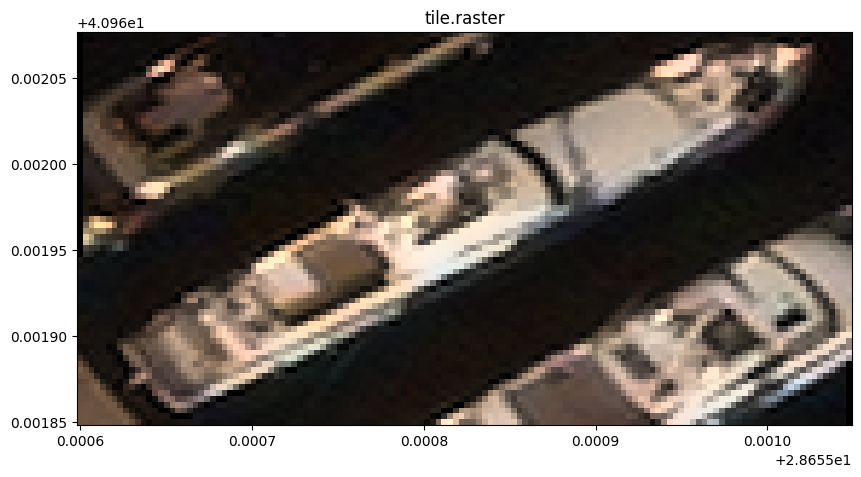

<Axes: title={'center': 'tile.raster'}>

In [0]:
clip_raster = clip_row['tile_clip']['raster']
plot_raster(clip_raster)

Multi-layer view: the clipped aerial tile with the detected-object vector boundary — pan and zoom to inspect the clip.

In [0]:
if INTERACTIVE_PLOTS:
    from databricks.labs.gbx.vizx import raster_layer, vector_layer, plot_interactive, as_gdf
    # xvo_df holds the object WKT geometries; as_gdf converts to GeoDataFrame for the vector layer
    objects_gdf = as_gdf(xvo_df.filter("type_name = 'Yacht'"), wkt_col="wkt_clip")
    plot_interactive([
        raster_layer(clip_raster),
        vector_layer(objects_gdf, color="#ff3", width=2),
    ])

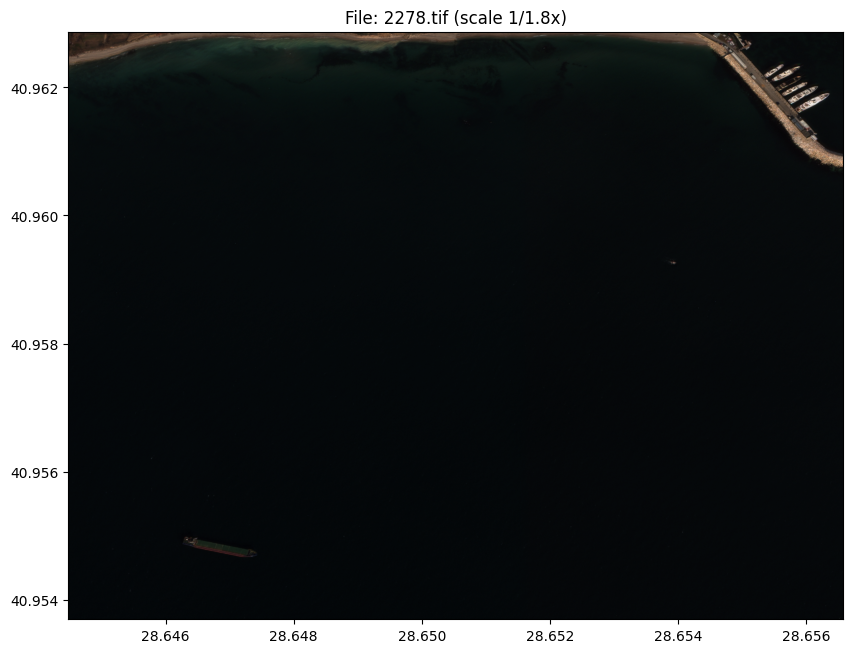

<Axes: title={'center': 'File: 2278.tif (scale 1/1.8x)'}>

In [0]:
clip_path = clip_row['image_path']
plot_file(clip_path)

## [5] Write the clipped rasters to Volumes

In [0]:
CLIP_DIR = VOL_BASE_DIR + "/clip"
dbutils.fs.mkdirs(f"dbfs:" + CLIP_DIR)

True

In [0]:
# Write the clipped rasters out with the lightweight gtiff_gbx writer.
# Deterministic filenames via nameCol: the writer enforces the exact
# (source, tile) schema, so put the desired name in `source` and point
# nameCol at it -> the writer emits <source>.tif (ext defaults to "tif").
(
  xvc_df
    .withColumn(
      "source",
      F.concat_ws("_", "index_right", "type_id", "feature_id")
    )
    .selectExpr("source", "tile_clip as tile") # <- exact (source, tile) schema
    .repartition(64, "source")
    .write
      .format("gtiff_gbx")
      .option("nameCol", "source")
      .mode("overwrite")
      .save(CLIP_DIR)
)

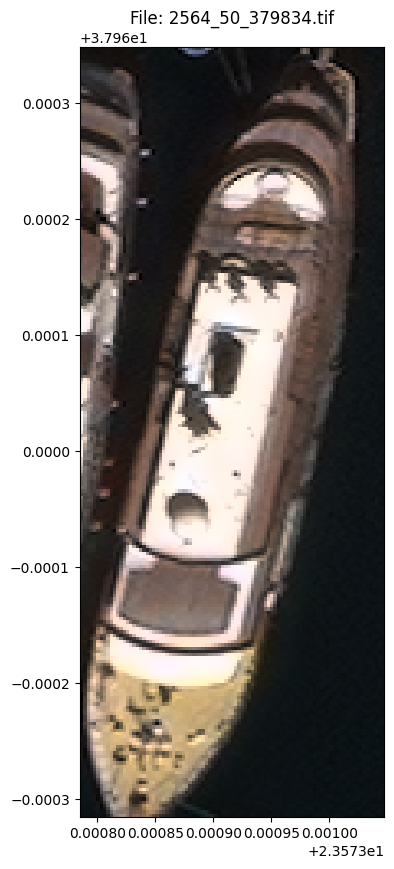

<Axes: title={'center': 'File: 2564_50_379834.tif'}>

In [0]:
plot_file(f"{CLIP_DIR}/2564_50_379834.tif")

_Uncomment the following within databricks for actual results._

In [0]:
displayHTML("""<img src="data:image/jpeg;base64, ..." width="100%" />""")

In [0]:
clip_df = (
  spark
    .read
    .format("gtiff_gbx")
    .option("filterRegex", r".*\.tif$")
    .load(CLIP_DIR)
)
clip_df.limit(1).show(vertical=True)

-RECORD 0----------------------
 source | dbfs:/Volumes/geo... 
 tile   | {-1, NULL, /Volum... 



## Summary

> We demonstrated using a distributed raster API to load TIFs into tables and clip various identified objects. Here are the tables we generated. 

In [0]:
%sql show tables

database,tableName,isTemporary
xview,xview_object,false
xview,xview_object_clip,false
xview,xview_raster,false
